In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect()
clean_path = "/home/iai-labor/traffic_project/traffic_hourly_clean_v2.parquet"


In [2]:
con.sql(f"DESCRIBE SELECT * FROM read_parquet('{clean_path}')").df()

,column_name,column_type,null,key,default,extra
0,SENSOR_ID,BIGINT,YES,None,None,None
1,DATETIME,TIMESTAMP,YES,None,None,None
2,TRAFFIC_INTENSITY,DOUBLE,YES,None,None,None
3,ELEMENT_TYPE,VARCHAR,YES,None,None,None
4,OCCUPANCY,DOUBLE,YES,None,None,None
5,LOAD,DOUBLE,YES,None,None,None
6,AVERAGE_SPEED,DOUBLE,YES,None,None,None
7,ERROR_FLAG,VARCHAR,YES,None,None,None
8,LONGITUDE,DOUBLE,YES,None,None,None
9,LATITUDE,DOUBLE,YES,None,None,None


In [3]:
import pandas as pd
sensor_road_attrs = pd.read_parquet("/home/iai-labor/traffic_project/sensor_road_attributes.parquet")
weird_urb = sensor_road_attrs[
    (sensor_road_attrs["ELEMENT_TYPE"] == "URB") &
    (sensor_road_attrs["highway"].isin(["motorway", "trunk", "motorway_link", "trunk_link"]))
]
ramp_sensor_ids = weird_urb["SENSOR_ID"].tolist()
print(len(ramp_sensor_ids))  # should be 143

145


In [4]:
import duckdb
con = duckdb.connect()
clean_path = "/home/iai-labor/traffic_project/traffic_hourly_clean_v2.parquet"

# Your ramp/connector sensor list from earlier (the 143 sensors that matched
# motorway_link/trunk in the OSM join)
ramp_sensor_ids = weird_urb["SENSOR_ID"].tolist()  # re-load this list if not in memory — see below

con.sql(f"""
    COPY (
        SELECT *,
            CASE
                WHEN ELEMENT_TYPE = 'URB' AND SENSOR_ID IN ({",".join(map(str, ramp_sensor_ids))})
                    THEN 'URB_ramp'
                WHEN ELEMENT_TYPE = 'URB'
                    THEN 'URB_normal'
                ELSE ELEMENT_TYPE
            END AS ROAD_SUBCLASS
        FROM read_parquet('{clean_path}')
    ) TO '/home/iai-labor/traffic_project/traffic_hourly_clean_v3.parquet' (FORMAT PARQUET, COMPRESSION 'snappy')
""")

In [5]:
con.sql("""
    SELECT ROAD_SUBCLASS, COUNT(*) AS n_rows, COUNT(DISTINCT SENSOR_ID) AS n_sensors
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_hourly_clean_v3.parquet')
    GROUP BY ROAD_SUBCLASS
""").show()

┌───────────────┬───────────┬───────────┐
│ ROAD_SUBCLASS │  n_rows   │ n_sensors │
│    varchar    │   int64   │   int64   │
├───────────────┼───────────┼───────────┤
│ URB_normal    │ 123496359 │      4295 │
│ URB_ramp      │   4168569 │       145 │
│ C30           │   3674931 │       143 │
│ M30           │   8647149 │       304 │
└───────────────┴───────────┴───────────┘



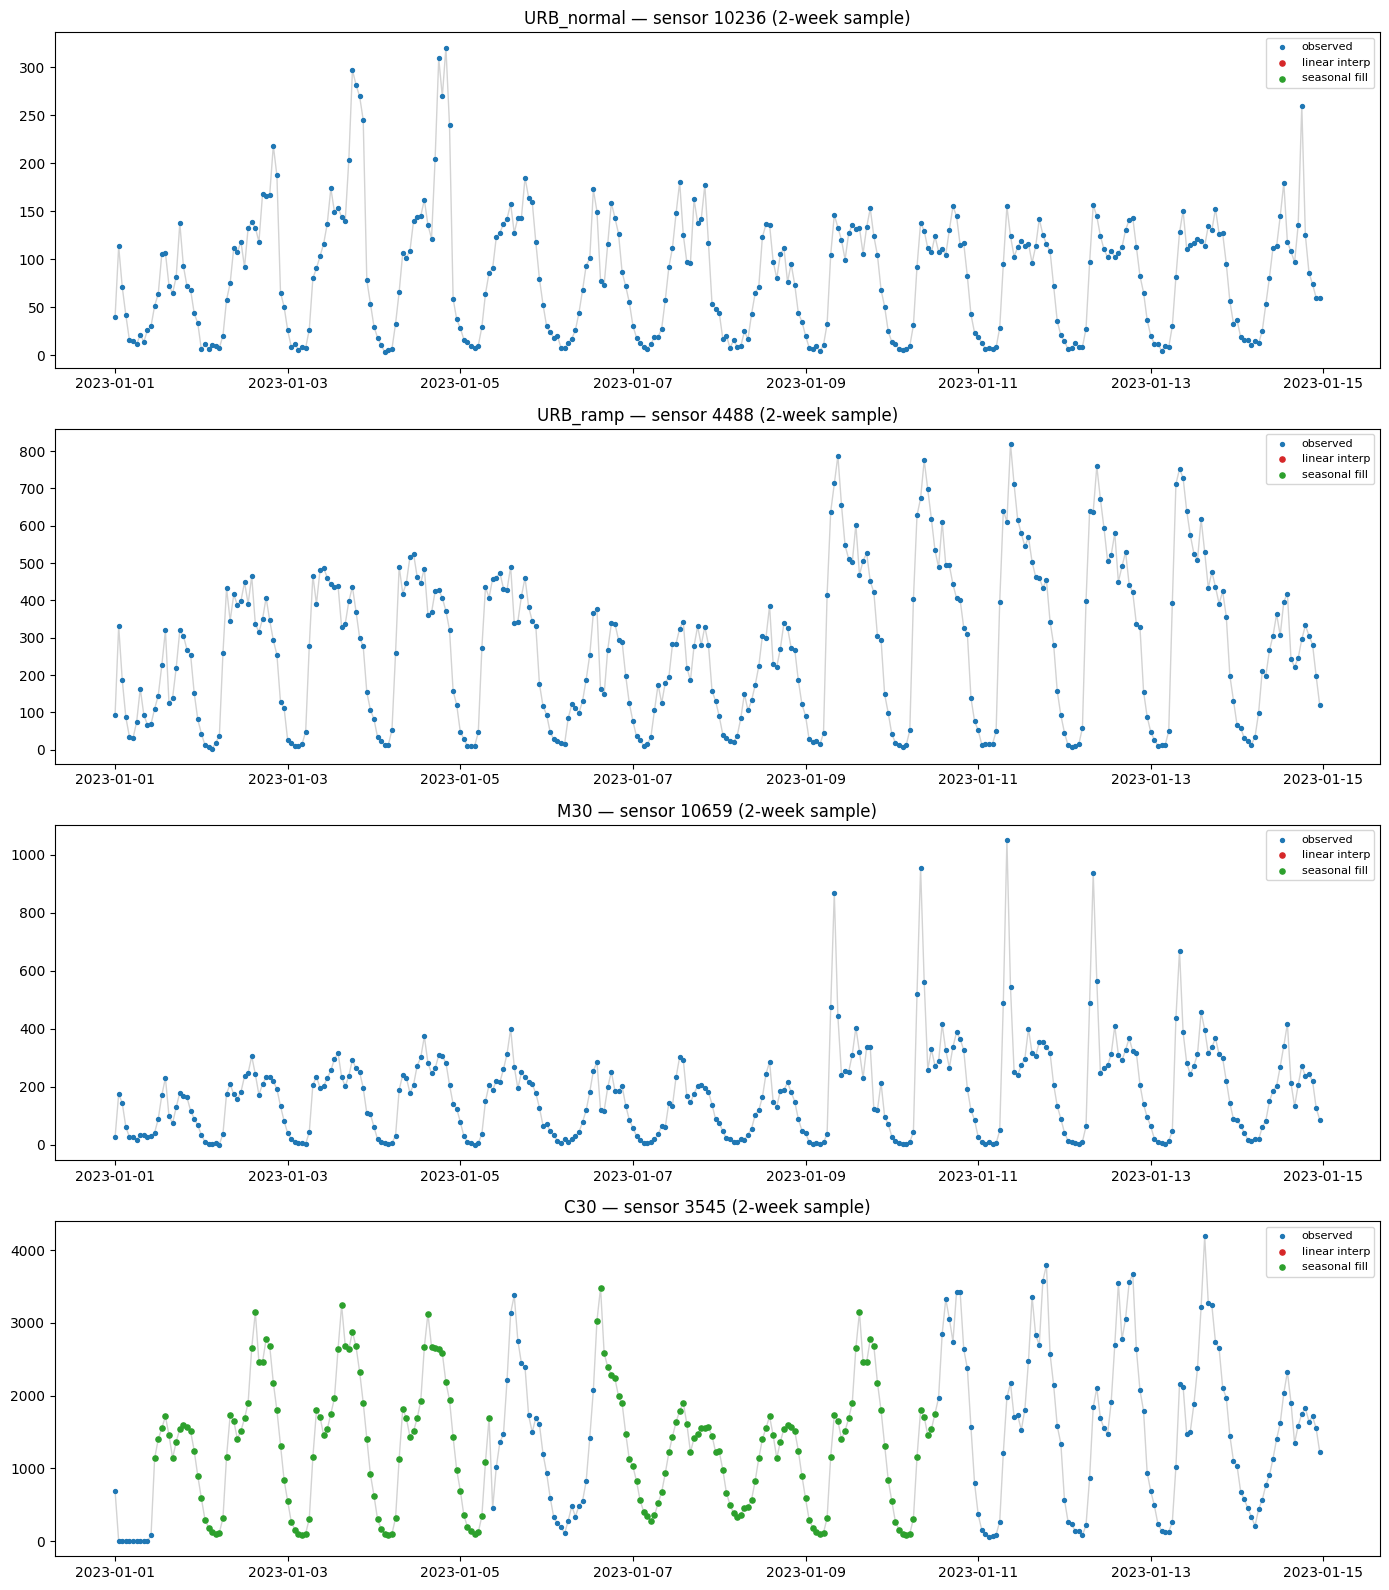

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

clean_path = "/home/iai-labor/traffic_project/traffic_hourly_clean_v3.parquet"

fixed_sensors = {
    "URB_normal": 10236,
    "URB_ramp": 4488,
    "M30": 10659,
    "C30": 3545,
}

fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=False)

for ax, (label, sensor_id) in zip(axes, fixed_sensors.items()):
    df = con.sql(f"""
        SELECT DATETIME, TRAFFIC_INTENSITY_FINAL, IS_IMPUTED_V2, IS_SEASONAL_FILLED
        FROM read_parquet('{clean_path}')
        WHERE SENSOR_ID = {sensor_id}
        ORDER BY DATETIME
        LIMIT 336
    """).df()

    ax.plot(df["DATETIME"], df["TRAFFIC_INTENSITY_FINAL"], color="lightgray", linewidth=1, zorder=1)
    obs = df[~df["IS_IMPUTED_V2"] & ~df["IS_SEASONAL_FILLED"]]
    interp = df[df["IS_IMPUTED_V2"]]
    seas = df[df["IS_SEASONAL_FILLED"]]

    ax.scatter(obs["DATETIME"], obs["TRAFFIC_INTENSITY_FINAL"], s=8, color="tab:blue", label="observed")
    ax.scatter(interp["DATETIME"], interp["TRAFFIC_INTENSITY_FINAL"], s=14, color="tab:red", label="linear interp")
    ax.scatter(seas["DATETIME"], seas["TRAFFIC_INTENSITY_FINAL"], s=14, color="tab:green", label="seasonal fill")
    ax.set_title(f"{label} — sensor {sensor_id} (2-week sample)")
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.savefig("/home/iai-labor/traffic_project/final_provenance_by_subclass.png", dpi=200)
plt.show()

In [8]:
# Quick check: is exact-zero common and is it concentrated on holidays for C30?
con.sql(f"""
    SELECT DATETIME, TRAFFIC_INTENSITY_FINAL, IS_STUCK, IS_SEASONAL_FILLED
    FROM read_parquet('{clean_path}')
    WHERE SENSOR_ID = 3545 AND DATETIME BETWEEN '2023-01-01' AND '2023-01-02'
    ORDER BY DATETIME
""").df()

,DATETIME,TRAFFIC_INTENSITY_FINAL,IS_STUCK,IS_SEASONAL_FILLED
0,2023-01-01 00:00:00,690.00,False,False
1,2023-01-01 01:00:00,0.00,False,False
2,2023-01-01 02:00:00,0.00,False,False
3,2023-01-01 03:00:00,0.00,False,False
4,2023-01-01 04:00:00,0.00,False,False
5,2023-01-01 05:00:00,0.00,False,False
6,2023-01-01 06:00:00,0.00,False,False
7,2023-01-01 07:00:00,0.00,False,False
8,2023-01-01 08:00:00,0.00,False,False
9,2023-01-01 09:00:00,0.00,False,False


In [9]:
df_hourly_profile = con.sql(f"""
    SELECT 
        ROAD_SUBCLASS,
        EXTRACT(hour FROM DATETIME) AS hour,
        CASE WHEN EXTRACT(dow FROM DATETIME) IN (0, 6) THEN 'weekend' ELSE 'weekday' END AS day_type,
        AVG(TRAFFIC_INTENSITY_FINAL) AS avg_intensity
    FROM read_parquet('{clean_path}')
    GROUP BY ROAD_SUBCLASS, hour, day_type
    ORDER BY ROAD_SUBCLASS, day_type, hour
""").df()

df_hourly_profile.head()

,ROAD_SUBCLASS,hour,day_type,avg_intensity
0,C30,0,weekday,336.857868
1,C30,1,weekday,193.870232
2,C30,2,weekday,123.262685
3,C30,3,weekday,94.326297
4,C30,4,weekday,92.206181


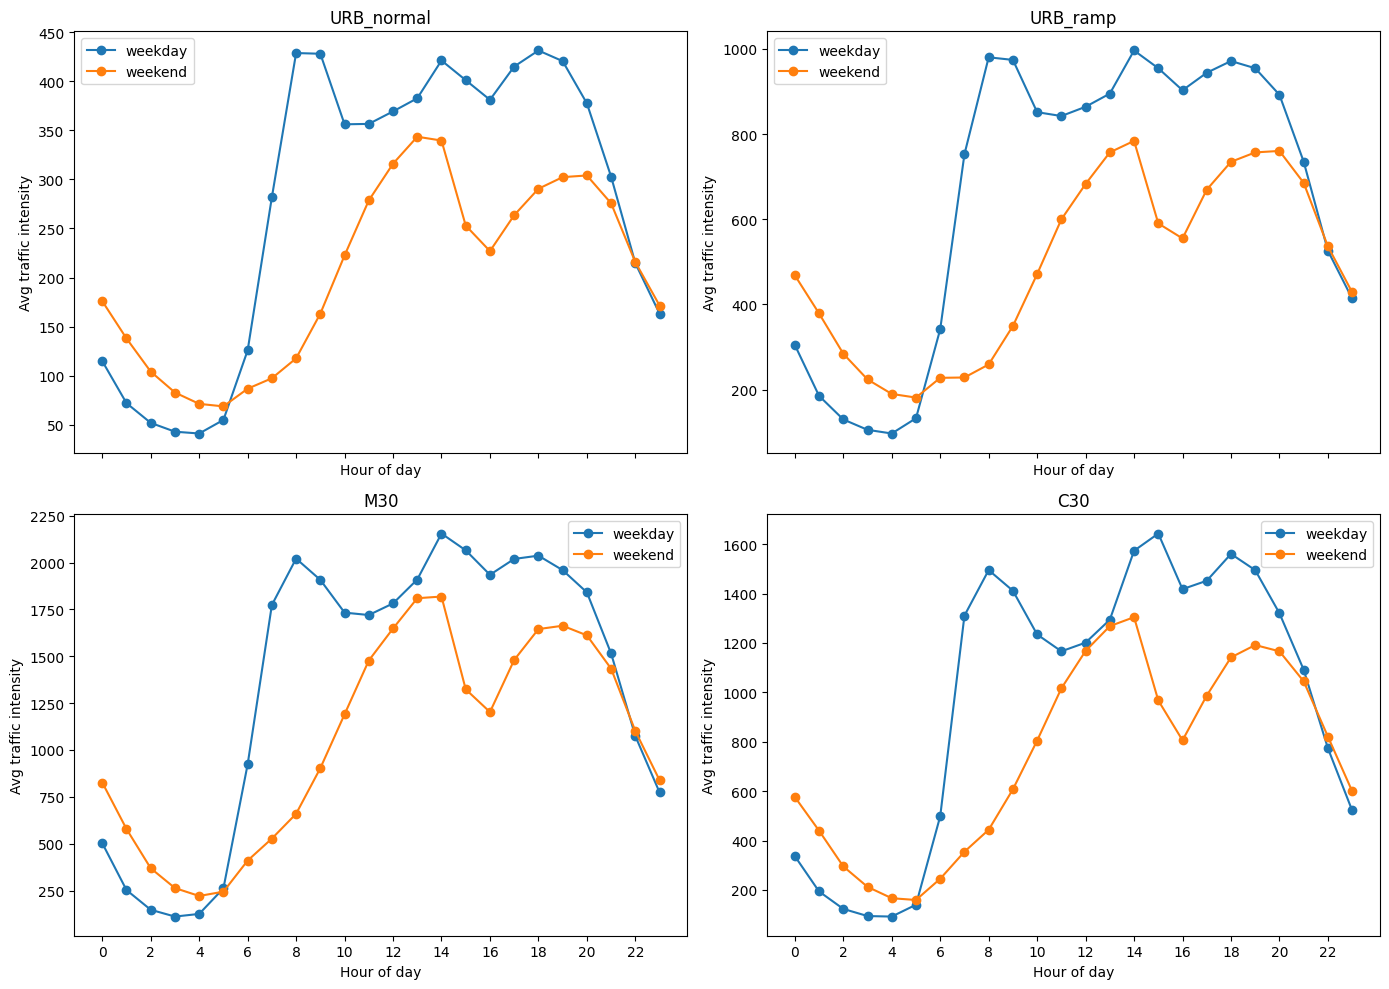

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
classes = ["URB_normal", "URB_ramp", "M30", "C30"]

for ax, cls in zip(axes.flat, classes):
    sub = df_hourly_profile[df_hourly_profile["ROAD_SUBCLASS"] == cls]
    for day_type, color in [("weekday", "tab:blue"), ("weekend", "tab:orange")]:
        s = sub[sub["day_type"] == day_type].sort_values("hour")
        ax.plot(s["hour"], s["avg_intensity"], marker="o", color=color, label=day_type)
    ax.set_title(cls)
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Avg traffic intensity")
    ax.legend()
    ax.set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.savefig("/home/iai-labor/traffic_project/daily_profile_by_subclass.png", dpi=200)
plt.show()

In [11]:
# Check whether the C30 14-15h peak is driven by genuinely observed data or inflated by seasonal fill
con.sql(f"""
    SELECT EXTRACT(hour FROM DATETIME) AS hour,
           AVG(TRAFFIC_INTENSITY_FINAL) FILTER (WHERE NOT IS_SEASONAL_FILLED AND NOT IS_IMPUTED_V2) AS avg_observed_only,
           AVG(TRAFFIC_INTENSITY_FINAL) AS avg_all,
           COUNT(*) FILTER (WHERE IS_SEASONAL_FILLED) * 100.0 / COUNT(*) AS pct_seasonal_filled
    FROM read_parquet('{clean_path}')
    WHERE ROAD_SUBCLASS = 'C30' AND EXTRACT(dow FROM DATETIME) NOT IN (0,6)
    GROUP BY hour ORDER BY hour
""").df()

,hour,avg_observed_only,avg_all,pct_seasonal_filled
0,0,329.145608,336.857868,14.394861
1,1,184.371906,193.870232,14.474467
2,2,111.613367,123.262685,14.479957
3,3,81.503921,94.326297,14.387541
4,4,78.849161,92.206181,14.378391
5,5,127.677287,140.098664,14.372901
6,6,492.248773,498.358253,14.380221
7,7,1309.368141,1310.879263,14.453422
8,8,1496.797529,1495.116584,14.447932
9,9,1413.678462,1411.508527,14.207285


In [12]:
df_weekly = con.sql(f"""
    SELECT 
        ROAD_SUBCLASS,
        EXTRACT(dow FROM DATETIME) AS dow,
        EXTRACT(hour FROM DATETIME) AS hour,
        AVG(TRAFFIC_INTENSITY_FINAL) AS avg_intensity
    FROM read_parquet('{clean_path}')
    GROUP BY ROAD_SUBCLASS, dow, hour
    ORDER BY ROAD_SUBCLASS, dow, hour
""").df()

df_weekly.head()

,ROAD_SUBCLASS,dow,hour,avg_intensity
0,C30,0,0,618.127151
1,C30,0,1,473.986028
2,C30,0,2,315.315382
3,C30,0,3,223.758481
4,C30,0,4,173.230604


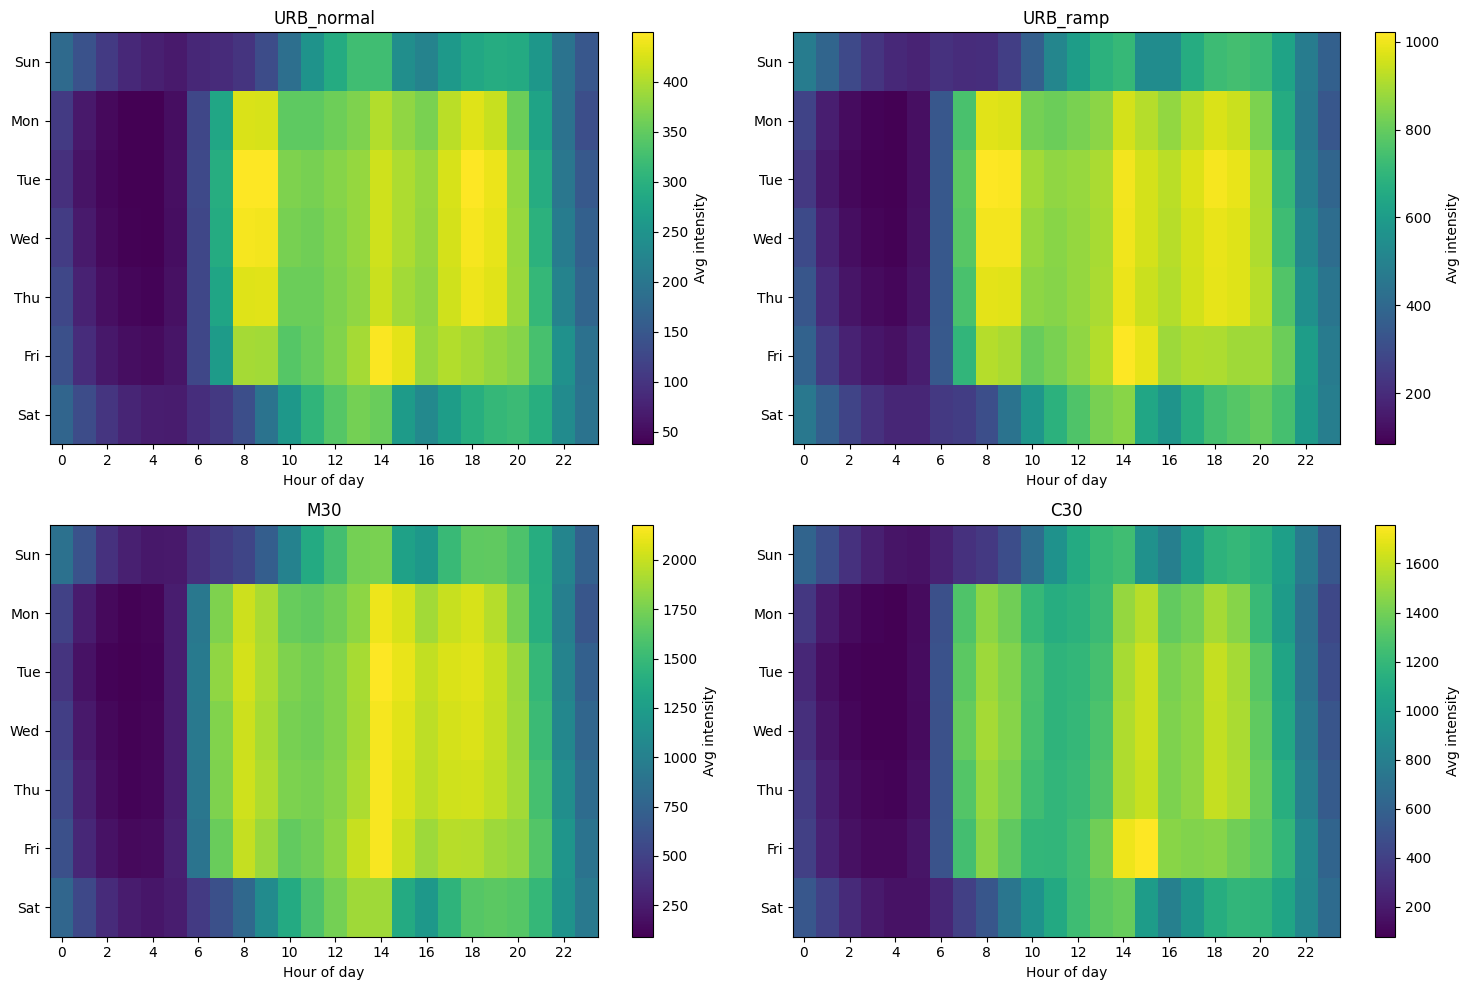

In [13]:
import numpy as np

dow_labels = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]  # DuckDB's EXTRACT(dow) = 0 is Sunday

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
classes = ["URB_normal", "URB_ramp", "M30", "C30"]

for ax, cls in zip(axes.flat, classes):
    sub = df_weekly[df_weekly["ROAD_SUBCLASS"] == cls]
    pivot = sub.pivot(index="dow", columns="hour", values="avg_intensity")
    pivot = pivot.reindex(index=range(7))  # ensure 0-6 order

    im = ax.imshow(pivot.values, aspect="auto", cmap="viridis")
    ax.set_yticks(range(7))
    ax.set_yticklabels(dow_labels)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hour of day")
    ax.set_title(cls)
    plt.colorbar(im, ax=ax, label="Avg intensity")

plt.tight_layout()
plt.savefig("/home/iai-labor/traffic_project/weekly_heatmap_by_subclass.png", dpi=200)
plt.show()

In [16]:
import holidays
import pandas as pd

madrid_holidays = holidays.Spain(subdiv="MD", years=range(2023, 2027))
print(list(madrid_holidays.items())[:5])  # quick sanity check

[(datetime.date(2024, 1, 1), "New Year's Day"), (datetime.date(2024, 1, 6), 'Epiphany'), (datetime.date(2024, 3, 29), 'Good Friday'), (datetime.date(2024, 5, 1), 'Labor Day'), (datetime.date(2024, 8, 15), 'Assumption Day')]


In [17]:
# Build a small holiday lookup table and register it with DuckDB
holiday_df = pd.DataFrame({"date": pd.to_datetime(list(madrid_holidays.keys()))})
holiday_df["date"] = holiday_df["date"].dt.date

con.register("holiday_lookup", holiday_df)

holiday_profile = con.sql(f"""
    SELECT 
        ROAD_SUBCLASS,
        EXTRACT(hour FROM DATETIME) AS hour,
        CASE WHEN h.date IS NOT NULL THEN 'holiday' ELSE 'regular_weekday' END AS day_type,
        AVG(TRAFFIC_INTENSITY_FINAL) AS avg_intensity
    FROM read_parquet('{clean_path}') t
    LEFT JOIN holiday_lookup h ON CAST(t.DATETIME AS DATE) = h.date
    WHERE EXTRACT(dow FROM t.DATETIME) BETWEEN 1 AND 5  -- weekdays only, exclude weekends from comparison
    GROUP BY ROAD_SUBCLASS, hour, day_type
    ORDER BY ROAD_SUBCLASS, day_type, hour
""").df()

holiday_profile.head(10)

,ROAD_SUBCLASS,hour,day_type,avg_intensity
0,C30,0,holiday,422.727404
1,C30,1,holiday,383.684179
2,C30,2,holiday,274.866398
3,C30,3,holiday,172.061093
4,C30,4,holiday,123.391916
5,C30,5,holiday,126.595420
6,C30,6,holiday,263.081351
7,C30,7,holiday,503.215845
8,C30,8,holiday,564.034460
9,C30,9,holiday,603.103892


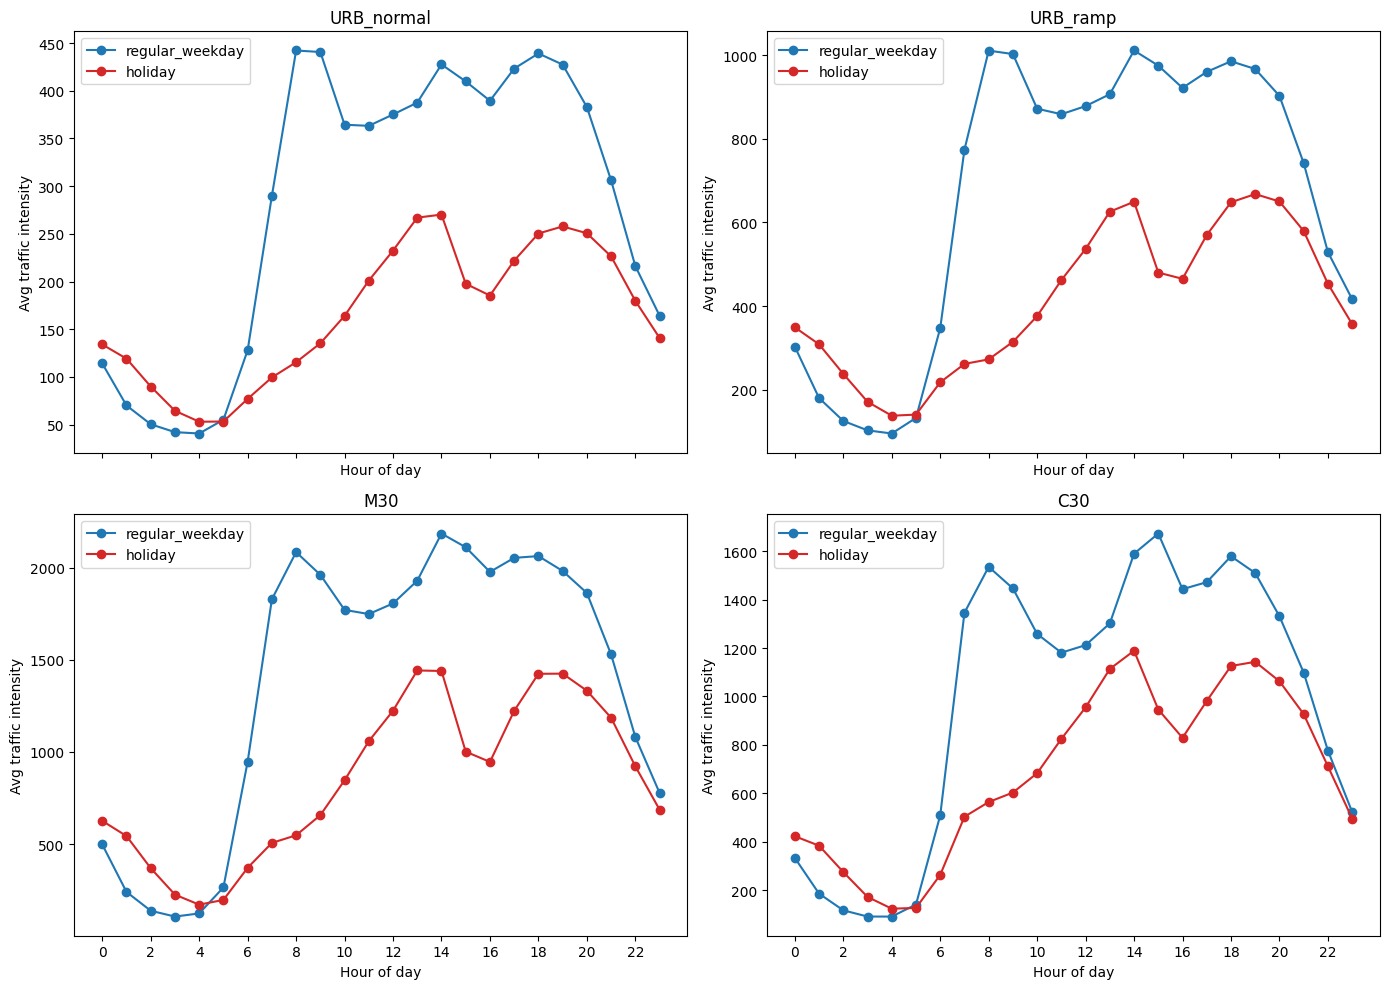

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
classes = ["URB_normal", "URB_ramp", "M30", "C30"]

for ax, cls in zip(axes.flat, classes):
    sub = holiday_profile[holiday_profile["ROAD_SUBCLASS"] == cls]
    for day_type, color in [("regular_weekday", "tab:blue"), ("holiday", "tab:red")]:
        s = sub[sub["day_type"] == day_type].sort_values("hour")
        ax.plot(s["hour"], s["avg_intensity"], marker="o", color=color, label=day_type)
    ax.set_title(cls)
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Avg traffic intensity")
    ax.legend()
    ax.set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.savefig("/home/iai-labor/traffic_project/holiday_vs_regular_by_subclass.png", dpi=200)
plt.show()

In [19]:
import pandas as pd
sensor_road_attrs = pd.read_parquet("/home/iai-labor/traffic_project/sensor_road_attributes.parquet")
print(sensor_road_attrs["lanes"].value_counts(dropna=False))
print(f"\nMissing lanes: {sensor_road_attrs['lanes'].isna().sum()} of {len(sensor_road_attrs)}")

lanes
2      1781
3       890
4       878
1       561
NaN     507
6       132
5        93
7         3
Name: count, dtype: int64

Missing lanes: 507 of 4845


In [20]:
case_study_sensors = {
    "URB_normal": 10236,
    "URB_ramp": 4488,
    "M30": 10659,
    "C30": 3545,
}

for label, sid in case_study_sensors.items():
    row = sensor_road_attrs[sensor_road_attrs["SENSOR_ID"] == sid]
    print(label, sid)
    print(row[["LATITUDE", "LONGITUDE", "highway", "lanes", "oneway", "maxspeed", "name"]])
    print(f"Google Maps: https://www.google.com/maps?q={row['LATITUDE'].values[0]},{row['LONGITUDE'].values[0]}")
    print()

URB_normal 10236
       LATITUDE  LONGITUDE      highway lanes  oneway maxspeed  \
3718  40.405738  -3.753463  residential   NaN    True      NaN   

                     name  
3718  Calle de Villamanín  
Google Maps: https://www.google.com/maps?q=40.40573774872745,-3.75346273199658

URB_ramp 4488
       LATITUDE  LONGITUDE        highway lanes  oneway maxspeed name
1018  40.434115  -3.736598  motorway_link     1    True       40  NaN
Google Maps: https://www.google.com/maps?q=40.43411462619254,-3.73659753740803

M30 10659
       LATITUDE  LONGITUDE   highway lanes  oneway maxspeed      name
4106  40.461579  -3.746282  motorway     4    True       90  Calle 30
Google Maps: https://www.google.com/maps?q=40.4615791908102,-3.74628224390707

C30 3545
     LATITUDE  LONGITUDE   highway lanes  oneway maxspeed  \
183   40.4097  -3.741094  motorway     3    True       70   

                     name  
183  Autovía del Suroeste  
Google Maps: https://www.google.com/maps?q=40.40969977823519,-3

In [21]:
sensor_road_attrs["lanes_numeric"] = pd.to_numeric(sensor_road_attrs["lanes"], errors="coerce")

lane_summary = sensor_road_attrs.groupby("ELEMENT_TYPE")["lanes_numeric"].agg(
    count="count", mean="mean", median="median",
    n_missing=lambda x: x.isna().sum()
)
print(lane_summary)

ramp_ids = set(weird_urb["SENSOR_ID"])
sensor_road_attrs["sub_group"] = sensor_road_attrs.apply(
    lambda r: "URB_ramp" if (r["ELEMENT_TYPE"] == "URB" and r["SENSOR_ID"] in ramp_ids)
    else ("URB_normal" if r["ELEMENT_TYPE"] == "URB" else r["ELEMENT_TYPE"]),
    axis=1
)
print(sensor_road_attrs.groupby("sub_group")["lanes_numeric"].agg(
    count="count", mean="mean", median="median"
))

              count      mean  median  n_missing
ELEMENT_TYPE                                    
C30             141  2.007092     2.0          3
M30             298  2.463087     3.0          2
URB            3899  2.709926     2.0        502
            count      mean  median
sub_group                          
C30           141  2.007092     2.0
M30           298  2.463087     3.0
URB_normal   3759  2.724927     2.0
URB_ramp      140  2.307143     2.0


In [22]:
print("Newly-NaN from coercion:", 
      sensor_road_attrs["lanes_numeric"].isna().sum() - sensor_road_attrs["lanes"].isna().sum())

Newly-NaN from coercion: 0


In [23]:
case_study_sensors = {
    "URB_normal": 10236,
    "URB_ramp": 4488,
    "M30": 10659,
    "C30": 3545,
}

for label, sid in case_study_sensors.items():
    row = sensor_road_attrs[sensor_road_attrs["SENSOR_ID"] == sid]
    if row.empty:
        print(label, sid, "— not found, check ID")
        continue
    lat, lon = row["LATITUDE"].values[0], row["LONGITUDE"].values[0]
    print(f"--- {label} — sensor {sid} ---")
    print(row[["highway", "lanes_numeric", "oneway", "maxspeed", "name"]].to_string(index=False))
    print(f"Google Maps: https://www.google.com/maps?q={lat},{lon}")
    print()

--- URB_normal — sensor 10236 ---
    highway  lanes_numeric  oneway maxspeed                name
residential            NaN    True      NaN Calle de Villamanín
Google Maps: https://www.google.com/maps?q=40.40573774872745,-3.75346273199658

--- URB_ramp — sensor 4488 ---
      highway  lanes_numeric  oneway maxspeed name
motorway_link            1.0    True       40  NaN
Google Maps: https://www.google.com/maps?q=40.43411462619254,-3.73659753740803

--- M30 — sensor 10659 ---
 highway  lanes_numeric  oneway maxspeed     name
motorway            4.0    True       90 Calle 30
Google Maps: https://www.google.com/maps?q=40.4615791908102,-3.74628224390707

--- C30 — sensor 3545 ---
 highway  lanes_numeric  oneway maxspeed                 name
motorway            3.0    True       70 Autovía del Suroeste
Google Maps: https://www.google.com/maps?q=40.40969977823519,-3.74109413305059



In [24]:
# Where are the extreme intensity values coming from?
extreme = con.sql(f"""
    SELECT 
        t.SENSOR_ID,
        t.ROAD_SUBCLASS,
        t.TRAFFIC_INTENSITY_FINAL,
        t.OCCUPANCY,
        s.highway,
        s.lanes_numeric,
        s.oneway,
        s.maxspeed,
        s.name,
        s.LATITUDE,
        s.LONGITUDE
    FROM read_parquet('{clean_path}') t
    LEFT JOIN sensor_road_attrs s ON t.SENSOR_ID = s.SENSOR_ID
    WHERE t.TRAFFIC_INTENSITY_FINAL > 20000
    ORDER BY t.TRAFFIC_INTENSITY_FINAL DESC
""").df()

print(extreme.shape)
print(extreme["ROAD_SUBCLASS"].value_counts())
print()
print(extreme["highway"].value_counts())
print()
print(extreme["lanes_numeric"].value_counts(dropna=False))

(426, 11)
ROAD_SUBCLASS
URB_normal    395
URB_ramp       31
Name: count, dtype: int64

highway
tertiary         219
secondary        140
primary           33
motorway          15
motorway_link      9
trunk              7
residential        3
Name: count, dtype: int64

lanes_numeric
4.0    228
3.0    146
2.0     28
6.0     20
5.0      3
1.0      1
Name: count, dtype: int64


In [25]:
# Which specific sensors are generating these spikes, and how often?
spike_sensors = con.sql(f"""
    SELECT 
        t.SENSOR_ID,
        t.ROAD_SUBCLASS,
        s.highway,
        s.lanes_numeric,
        s.name,
        s.LATITUDE,
        s.LONGITUDE,
        COUNT(*) AS n_spikes,
        AVG(t.TRAFFIC_INTENSITY_FINAL) AS avg_spike_intensity,
        MAX(t.TRAFFIC_INTENSITY_FINAL) AS max_spike_intensity,
        AVG(t.OCCUPANCY) AS avg_occupancy_during_spike
    FROM read_parquet('{clean_path}') t
    LEFT JOIN sensor_road_attrs s ON t.SENSOR_ID = s.SENSOR_ID
    WHERE t.TRAFFIC_INTENSITY_FINAL > 20000
    GROUP BY t.SENSOR_ID, t.ROAD_SUBCLASS, s.highway, s.lanes_numeric, s.name, s.LATITUDE, s.LONGITUDE
    ORDER BY n_spikes DESC
""").df()

print(spike_sensors)

    SENSOR_ID ROAD_SUBCLASS        highway  lanes_numeric  \
0        7023    URB_normal       tertiary            4.0   
1       10674    URB_normal      secondary            3.0   
2        5465    URB_normal      secondary            3.0   
3        5470    URB_normal      secondary            3.0   
4        6070    URB_normal        primary            3.0   
5        5468    URB_normal      secondary            6.0   
6       10463      URB_ramp       motorway            3.0   
7        5767    URB_normal      secondary            2.0   
8        6095      URB_ramp  motorway_link            2.0   
9        4059    URB_normal        primary            4.0   
10       5427      URB_ramp          trunk            3.0   
11       7112    URB_normal      secondary            2.0   
12       5429      URB_ramp       motorway            3.0   
13       5824    URB_normal      secondary            3.0   
14       5377    URB_normal        primary            3.0   
15       6940    URB_nor

In [26]:
# For each spiking sensor, compare its normal (non-spike) behavior
# to understand if these are isolated faults or recurrent patterns
spike_ids = spike_sensors["SENSOR_ID"].tolist()

normal_behavior = con.sql(f"""
    SELECT 
        SENSOR_ID,
        AVG(TRAFFIC_INTENSITY_FINAL) FILTER (WHERE TRAFFIC_INTENSITY_FINAL <= 20000) AS avg_normal,
        MEDIAN(TRAFFIC_INTENSITY_FINAL) FILTER (WHERE TRAFFIC_INTENSITY_FINAL <= 20000) AS median_normal,
        COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY_FINAL > 20000) AS n_spikes,
        COUNT(*) AS n_total,
        ROUND(100.0 * COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY_FINAL > 20000) / COUNT(*), 3) AS pct_spikes
    FROM read_parquet('{clean_path}')
    WHERE SENSOR_ID IN ({",".join(map(str, spike_ids))})
    GROUP BY SENSOR_ID
    ORDER BY n_spikes DESC
""").show()

┌───────────┬────────────────────┬───────────────┬──────────┬─────────┬────────────┐
│ SENSOR_ID │     avg_normal     │ median_normal │ n_spikes │ n_total │ pct_spikes │
│   int64   │       double       │    double     │  int64   │  int64  │   double   │
├───────────┼────────────────────┼───────────────┼──────────┼─────────┼────────────┤
│      7023 │ 137.53411685959523 │         125.0 │      214 │   29845 │      0.717 │
│     10674 │ 199.95266171567476 │        177.75 │       35 │   29928 │      0.117 │
│      5465 │  429.4912937195482 │         385.5 │       31 │   29928 │      0.104 │
│      5470 │ 335.30417185436704 │         318.5 │       20 │   29470 │      0.068 │
│      5468 │  858.6846728628263 │         883.0 │       17 │   29928 │      0.057 │
│      6070 │ 374.63888703152674 │         248.5 │       17 │   29928 │      0.057 │
│      5767 │  715.2444749919221 │         724.5 │       11 │   29928 │      0.037 │
│     10463 │ 1212.1554815545232 │       1354.25 │       11 │   2

In [27]:
import folium
from folium import plugins

# Top spiking sensors to show
spike_map_data = spike_sensors.head(30).copy()
spike_map_data = spike_map_data.dropna(subset=["LATITUDE", "LONGITUDE"])

m = folium.Map(location=[40.45, -3.685], zoom_start=12, tiles="cartodbpositron")

# Color by road subclass
colors = {"URB_normal": "blue", "URB_ramp": "orange", "M30": "red", "C30": "darkred"}

for _, row in spike_map_data.iterrows():
    color = colors.get(row["ROAD_SUBCLASS"], "gray")
    folium.CircleMarker(
        location=[row["LATITUDE"], row["LONGITUDE"]],
        radius=max(5, min(20, row["n_spikes"] / 10)),  # size proportional to spike count
        color=color, fill=True, fill_opacity=0.8,
        popup=folium.Popup(
            f"<b>Sensor {int(row['SENSOR_ID'])}</b><br>"
            f"Road: {row['name']}<br>"
            f"Class: {row['ROAD_SUBCLASS']}<br>"
            f"Highway: {row['highway']}<br>"
            f"Lanes: {row['lanes_numeric']}<br>"
            f"N spikes: {int(row['n_spikes'])}<br>"
            f"Avg spike intensity: {row['avg_spike_intensity']:.0f}<br>"
            f"Avg occupancy during spike: {row['avg_occupancy_during_spike']:.1f}%",
            max_width=250
        )
    ).add_to(m)

    # Add label with sensor ID directly on map
    folium.Marker(
        location=[row["LATITUDE"], row["LONGITUDE"]],
        icon=folium.DivIcon(
            html=f'<div style="font-size:8px;color:black;">{int(row["SENSOR_ID"])}</div>',
            icon_size=(40, 12), icon_anchor=(0, 0)
        )
    ).add_to(m)

# Add a legend
legend_html = """
<div style="position:fixed;bottom:30px;left:30px;z-index:1000;background:white;
     padding:10px;border:1px solid gray;font-size:12px;">
<b>Road subclass</b><br>
<span style="color:blue">●</span> URB_normal<br>
<span style="color:orange">●</span> URB_ramp<br>
<b>Circle size = spike frequency</b>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

m.save("/home/iai-labor/traffic_project/spike_sensors_map.html")
m

In [28]:
import folium

m = folium.Map(location=[40.45, -3.685], zoom_start=12, tiles="cartodbpositron")

# Draw cluster zones first (background circles)
clusters = [
    {"name": "Cluster A: Plaza de Castilla interchange", 
     "lat": 40.468, "lon": -3.697, "radius": 2000, "color": "red"},
    {"name": "Cluster B: Méndez Álvaro / M-30 south",  
     "lat": 40.402, "lon": -3.681, "radius": 1500, "color": "orange"},
    {"name": "Cluster C: Central arterials",            
     "lat": 40.435, "lon": -3.673, "radius": 2500, "color": "purple"},
]

for c in clusters:
    folium.Circle(
        location=[c["lat"], c["lon"]], radius=c["radius"],
        color=c["color"], fill=True, fill_opacity=0.1,
        popup=c["name"]
    ).add_to(m)
    folium.Marker(
        location=[c["lat"], c["lon"]],
        icon=folium.DivIcon(
            html=f'<div style="font-size:11px;font-weight:bold;color:{c["color"]}">{c["name"]}</div>',
            icon_size=(300, 20), icon_anchor=(0, 0)
        )
    ).add_to(m)

# Plot sensors colored by fault vs real-congestion hypothesis
# Hypothesis: if avg_occupancy_during_spike < 30% but intensity > 20000 → likely sensor fault
# If avg_occupancy_during_spike >= 30% → more likely real congestion

for _, row in spike_sensors.head(30).iterrows():
    if pd.isna(row["LATITUDE"]):
        continue
    is_fault = row["avg_occupancy_during_spike"] < 30 and row["avg_spike_intensity"] > 30000
    color = "red" if is_fault else "green"
    label = "likely fault" if is_fault else "possible real congestion"
    
    folium.CircleMarker(
        location=[row["LATITUDE"], row["LONGITUDE"]],
        radius=max(5, min(25, row["n_spikes"] / 8)),
        color=color, fill=True, fill_opacity=0.85,
        popup=folium.Popup(
            f"<b>Sensor {int(row['SENSOR_ID'])}</b><br>"
            f"<b>{row['name']}</b><br>"
            f"Class: {row['ROAD_SUBCLASS']} | {row['highway']}<br>"
            f"Lanes: {row['lanes_numeric']}<br>"
            f"N spikes: {int(row['n_spikes'])}<br>"
            f"Avg intensity during spike: {row['avg_spike_intensity']:.0f}<br>"
            f"Avg occupancy during spike: {row['avg_occupancy_during_spike']:.1f}%<br>"
            f"Normal median intensity: <b>{row.get('median_normal', 'N/A')}</b><br>"
            f"Assessment: <b>{label}</b>",
            max_width=280
        )
    ).add_to(m)

# Legend
legend_html = """
<div style="position:fixed;bottom:30px;left:30px;z-index:1000;background:white;
     padding:12px;border:2px solid gray;font-size:12px;border-radius:5px;">
<b>Spike sensor assessment</b><br>
<span style="color:red">●</span> Likely sensor hardware fault<br>
<span style="color:green">●</span> Possible real congestion event<br><br>
<b>Circle size = spike frequency</b><br><br>
<span style="color:red">○</span> Cluster A: Plaza de Castilla<br>
<span style="color:orange">○</span> Cluster B: Méndez Álvaro<br>
<span style="color:purple">○</span> Cluster C: Central arterials
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))
m.save("/home/iai-labor/traffic_project/spike_clusters_map.html")
m